In [400]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
%matplotlib inline

In [401]:
df = pd.read_csv(r'/Users/pawn/Desktop/NTI/Adult Census Income.csv')

In [402]:
df.head()

,age,workclass,fnlwgt,education,education.num,marital.status,occupation,relationship,race,sex,capital.gain,capital.loss,hours.per.week,native.country,income
0,90,?,77053,HS-grad,9,Widowed,?,Not-in-family,White,Female,0,4356,40,United-States,<=50K
1,82,Private,132870,HS-grad,9,Widowed,Exec-managerial,Not-in-family,White,Female,0,4356,18,United-States,<=50K
2,66,?,186061,Some-college,10,Widowed,?,Unmarried,Black,Female,0,4356,40,United-States,<=50K
3,54,Private,140359,7th-8th,4,Divorced,Machine-op-inspct,Unmarried,White,Female,0,3900,40,United-States,<=50K
4,41,Private,264663,Some-college,10,Separated,Prof-specialty,Own-child,White,Female,0,3900,40,United-States,<=50K


In [403]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 32561 entries, 0 to 32560
Data columns (total 15 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   age             32561 non-null  int64 
 1   workclass       32561 non-null  object
 2   fnlwgt          32561 non-null  int64 
 3   education       32561 non-null  object
 4   education.num   32561 non-null  int64 
 5   marital.status  32561 non-null  object
 6   occupation      32561 non-null  object
 7   relationship    32561 non-null  object
 8   race            32561 non-null  object
 9   sex             32561 non-null  object
 10  capital.gain    32561 non-null  int64 
 11  capital.loss    32561 non-null  int64 
 12  hours.per.week  32561 non-null  int64 
 13  native.country  32561 non-null  object
 14  income          32561 non-null  object
dtypes: int64(6), object(9)
memory usage: 3.7+ MB


In [404]:
df.describe()

,age,fnlwgt,education.num,capital.gain,capital.loss,hours.per.week
count,32561.000000,3.256100e+04,32561.000000,32561.000000,32561.000000,32561.000000
mean,38.581647,1.897784e+05,10.080679,1077.648844,87.303830,40.437456
std,13.640433,1.055500e+05,2.572720,7385.292085,402.960219,12.347429
min,17.000000,1.228500e+04,1.000000,0.000000,0.000000,1.000000
25%,28.000000,1.178270e+05,9.000000,0.000000,0.000000,40.000000
50%,37.000000,1.783560e+05,10.000000,0.000000,0.000000,40.000000
75%,48.000000,2.370510e+05,12.000000,0.000000,0.000000,45.000000
max,90.000000,1.484705e+06,16.000000,99999.000000,4356.000000,99.000000


In [405]:
df.shape

(32561, 15)

In [406]:
df.isnull().sum()

age               0
workclass         0
fnlwgt            0
education         0
education.num     0
marital.status    0
occupation        0
relationship      0
race              0
sex               0
capital.gain      0
capital.loss      0
hours.per.week    0
native.country    0
income            0
dtype: int64

In [407]:
df.duplicated().sum()

np.int64(24)

In [408]:
df.drop_duplicates(inplace = True)

In [409]:
df.reset_index(drop=True, inplace=True)

In [410]:
df.duplicated().sum()

np.int64(0)

In [411]:
df.replace("?" , np.nan , inplace = True)

In [412]:
from sklearn.neighbors import KNeighborsClassifier

In [413]:
df.isnull().sum().sort_values(ascending = False)

occupation        1843
workclass         1836
native.country     582
age                  0
fnlwgt               0
education            0
education.num        0
marital.status       0
relationship         0
race                 0
sex                  0
capital.gain         0
capital.loss         0
hours.per.week       0
income               0
dtype: int64

In [414]:
df.shape

(32537, 15)

([0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13],
 [Text(0, 0, 'Exec-managerial'),
  Text(1, 0, 'Machine-op-inspct'),
  Text(2, 0, 'Prof-specialty'),
  Text(3, 0, 'Other-service'),
  Text(4, 0, 'Adm-clerical'),
  Text(5, 0, 'Craft-repair'),
  Text(6, 0, 'Transport-moving'),
  Text(7, 0, 'Handlers-cleaners'),
  Text(8, 0, 'Sales'),
  Text(9, 0, 'Farming-fishing'),
  Text(10, 0, 'Tech-support'),
  Text(11, 0, 'Protective-serv'),
  Text(12, 0, 'Armed-Forces'),
  Text(13, 0, 'Priv-house-serv')])

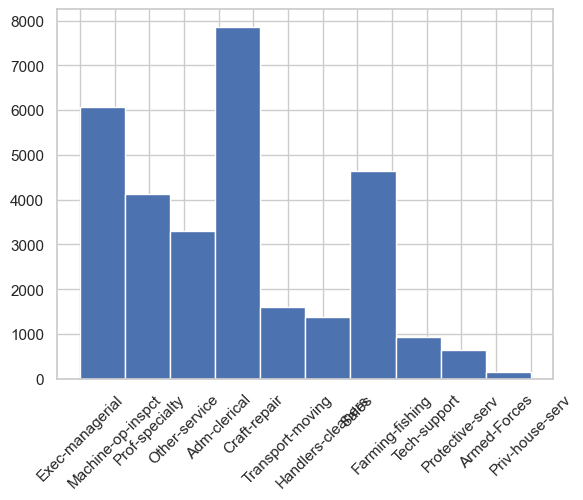

In [415]:
df['occupation'].hist()
plt.xticks(rotation=45)


In [416]:
from sklearn.impute import SimpleImputer

imputer = SimpleImputer(missing_values=np.nan, strategy='most_frequent')
# strategy = 'median', 'mean', 'constant', 'most_frequent'
imputer.fit(df[['occupation']])
df[['occupation']] = imputer.transform(df[['occupation']])

In [ ]:

from sklearn.impute import SimpleImputer

imputer = SimpleImputer(missing_values=np.nan, strategy='most_frequent')
# strategy = 'median', 'mean', 'constant', 'most_frequent'
imputer.fit(df[['workclass']])
df[['workclass']] = imputer.transform(df[['workclass']])

In [418]:
from sklearn.impute import SimpleImputer

imputer = SimpleImputer(missing_values=np.nan, strategy='most_frequent')
# strategy = 'median', 'mean', 'constant', 'most_frequent'
imputer.fit(df[['native.country']])
df[['native.country']] = imputer.transform(df[['native.country']])

In [419]:
df.select_dtypes(include=['object']).columns

Index(['workclass', 'education', 'marital.status', 'occupation',
       'relationship', 'race', 'sex', 'native.country', 'income'],
      dtype='object')

In [420]:
df.columns

Index(['age', 'workclass', 'fnlwgt', 'education', 'education.num',
       'marital.status', 'occupation', 'relationship', 'race', 'sex',
       'capital.gain', 'capital.loss', 'hours.per.week', 'native.country',
       'income'],
      dtype='object')

<Axes: >

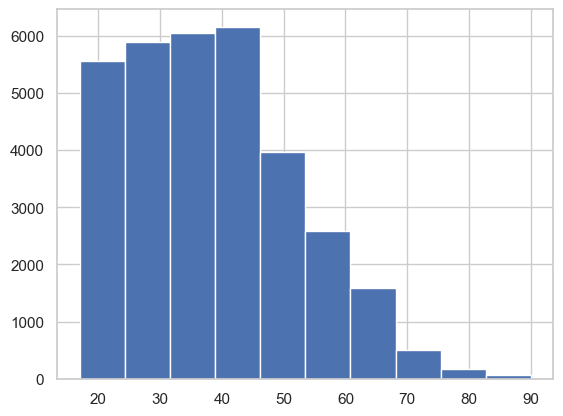

In [421]:
df['age'].hist()

In [422]:
df.head(10)

,age,workclass,fnlwgt,education,education.num,marital.status,occupation,relationship,race,sex,capital.gain,capital.loss,hours.per.week,native.country,income
0,90,Private,77053,HS-grad,9,Widowed,Prof-specialty,Not-in-family,White,Female,0,4356,40,United-States,<=50K
1,82,Private,132870,HS-grad,9,Widowed,Exec-managerial,Not-in-family,White,Female,0,4356,18,United-States,<=50K
2,66,Private,186061,Some-college,10,Widowed,Prof-specialty,Unmarried,Black,Female,0,4356,40,United-States,<=50K
3,54,Private,140359,7th-8th,4,Divorced,Machine-op-inspct,Unmarried,White,Female,0,3900,40,United-States,<=50K
4,41,Private,264663,Some-college,10,Separated,Prof-specialty,Own-child,White,Female,0,3900,40,United-States,<=50K
5,34,Private,216864,HS-grad,9,Divorced,Other-service,Unmarried,White,Female,0,3770,45,United-States,<=50K
6,38,Private,150601,10th,6,Separated,Adm-clerical,Unmarried,White,Male,0,3770,40,United-States,<=50K
7,74,State-gov,88638,Doctorate,16,Never-married,Prof-specialty,Other-relative,White,Female,0,3683,20,United-States,>50K
8,68,Federal-gov,422013,HS-grad,9,Divorced,Prof-specialty,Not-in-family,White,Female,0,3683,40,United-States,<=50K
9,41,Private,70037,Some-college,10,Never-married,Craft-repair,Unmarried,White,Male,0,3004,60,United-States,>50K


In [423]:
from sklearn.preprocessing import OneHotEncoder

In [424]:
onhot = OneHotEncoder(
                      sparse_output=False,
                      drop='first',
                      handle_unknown='ignore'
).set_output(transform='pandas')

In [425]:
for col in df.select_dtypes('object').columns:
    print(f"{col} number unique: ",df[col].nunique())
    print("-"*50)

workclass number unique:  8
--------------------------------------------------
education number unique:  16
--------------------------------------------------
marital.status number unique:  7
--------------------------------------------------
occupation number unique:  14
--------------------------------------------------
relationship number unique:  6
--------------------------------------------------
race number unique:  5
--------------------------------------------------
sex number unique:  2
--------------------------------------------------
native.country number unique:  41
--------------------------------------------------
income number unique:  2
--------------------------------------------------


In [426]:
for col in ['workclass', 'education', 'marital.status', 'occupation', 'relationship', 'race']:
    temp = onhot.fit_transform(df[[col]])
    df = pd.concat([df, temp], axis=1)


In [427]:
from sklearn.preprocessing import LabelEncoder
le = LabelEncoder()
df['native.country'] = le.fit_transform(df['native.country'])


In [428]:
# df.drop(['workclass', 'education', 'marital.status', 'occupation', 'relationship', 'race'] , inplace = True)

In [429]:
import category_encoders as ce


In [430]:
# encoder = ce.BinaryEncoder(cols=['sex' , 'income'])
# encoded = encoder.fit_transform(df)

# encoded.head()

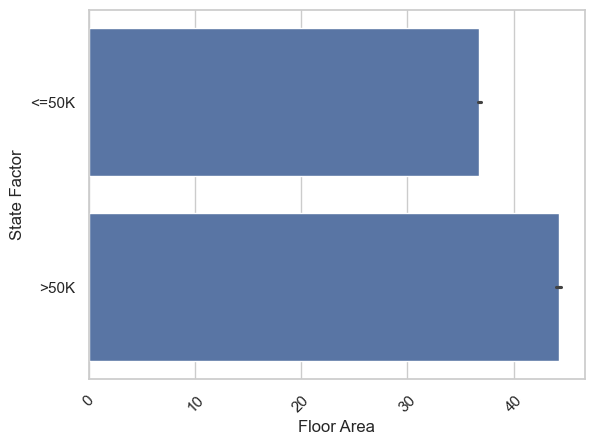

In [460]:
# sns.scatterplot(data = df[''] , x='workclass' , y='income')
sns.set(style='whitegrid' )
sns.barplot(data=df , x='age' , y='income')
plt.title('', fontsize=16, color='blue')
plt.xlabel('Floor Area')
plt.ylabel('State Factor')
plt.xticks(rotation=45)
plt.show()

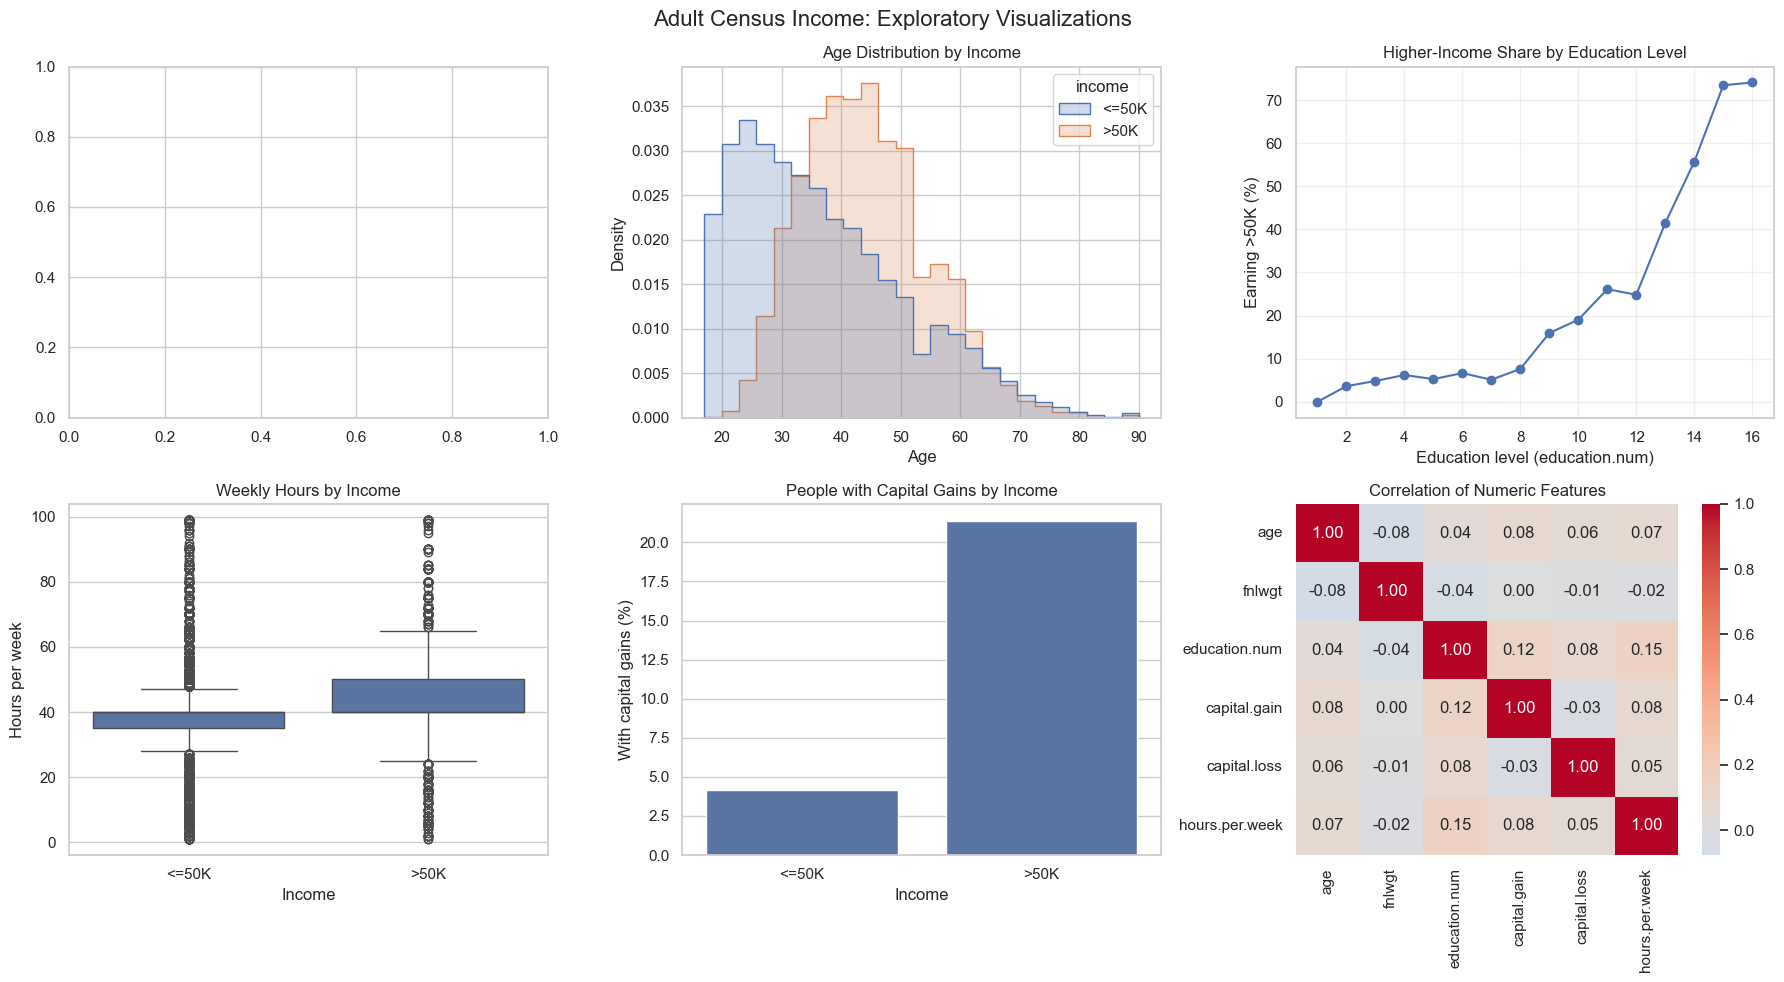

In [ ]:
# Prepare plotting data without modifying df
plot_df = df.copy()
plot_df['income'] = plot_df['income'].astype(str).str.strip()
plot_df['high_income'] = (plot_df['income'] == '>50K').astype(int)

fig, axes = plt.subplots(2, 3, figsize=(18, 10))
fig.suptitle('Adult Census Income: Exploratory Visualizations', fontsize=16)

# Income class balance
sns.countplot(data=plot_df, x='income', order=plot_df['income'].value_counts().index, ax=axes[0, 0])
axes[0, 0].set_title('Income Class Distribution')
axes[0, 0].set_xlabel('Income')
axes[0, 0].set_ylabel('Number of people')

# Age distribution by income
sns.histplot(
    data=plot_df, x='age', hue='income',
    bins=25, element='step', stat='density',
    common_norm=False, ax=axes[0, 1]
)
axes[0, 1].set_title('Age Distribution by Income')
axes[0, 1].set_xlabel('Age')
axes[0, 1].set_ylabel('Density')

# Share earning >50K by education level
education_rate = plot_df.groupby('education.num', observed=True)['high_income'].mean() * 100
axes[0, 2].plot(education_rate.index, education_rate.values, marker='o')
axes[0, 2].set_title('Higher-Income Share by Education Level')
axes[0, 2].set_xlabel('Education level (education.num)')
axes[0, 2].set_ylabel('Earning >50K (%)')
axes[0, 2].grid(alpha=0.3)

# Weekly hours by income
sns.boxplot(data=plot_df, x='income', y='hours.per.week', ax=axes[1, 0])
axes[1, 0].set_title('Weekly Hours by Income')
axes[1, 0].set_xlabel('Income')
axes[1, 0].set_ylabel('Hours per week')

# Share with any capital gains by income
capital_gain_share = (
    plot_df.assign(has_capital_gain=plot_df['capital.gain'] > 0)
    .groupby('income', observed=True)['has_capital_gain']
    .mean()
    .mul(100)
)
sns.barplot(x=capital_gain_share.index, y=capital_gain_share.values, ax=axes[1, 1])
axes[1, 1].set_title('People with Capital Gains by Income')
axes[1, 1].set_xlabel('Income')
axes[1, 1].set_ylabel('With capital gains (%)')

# Correlations among key numeric features
numeric_cols = [
    'age', 'fnlwgt', 'education.num',
    'capital.gain', 'capital.loss', 'hours.per.week'
]
corr = plot_df[numeric_cols].corr()
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', center=0, ax=axes[1, 2])
axes[1, 2].set_title('Correlation of Numeric Features')

plt.tight_layout()
plt.show()

In [432]:

df.drop(['workclass', 'education', 'marital.status', 'occupation', 'relationship', 'race', 'sex'],
        axis=1, inplace=True)

In [433]:
df.head(10)

,age,fnlwgt,education.num,capital.gain,capital.loss,hours.per.week,native.country,income,workclass_Local-gov,workclass_Never-worked,...,occupation_Transport-moving,relationship_Not-in-family,relationship_Other-relative,relationship_Own-child,relationship_Unmarried,relationship_Wife,race_Asian-Pac-Islander,race_Black,race_Other,race_White
0,90,77053,9,0,4356,40,38,<=50K,0.0,0.0,...,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
1,82,132870,9,0,4356,18,38,<=50K,0.0,0.0,...,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
2,66,186061,10,0,4356,40,38,<=50K,0.0,0.0,...,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0
3,54,140359,4,0,3900,40,38,<=50K,0.0,0.0,...,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0
4,41,264663,10,0,3900,40,38,<=50K,0.0,0.0,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0
5,34,216864,9,0,3770,45,38,<=50K,0.0,0.0,...,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0
6,38,150601,6,0,3770,40,38,<=50K,0.0,0.0,...,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0
7,74,88638,16,0,3683,20,38,>50K,0.0,0.0,...,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
8,68,422013,9,0,3683,40,38,<=50K,0.0,0.0,...,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
9,41,70037,10,0,3004,60,38,>50K,0.0,0.0,...,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0


In [434]:
df['age'].max(), df['age'].min()


(np.int64(90), np.int64(17))

In [435]:
df.columns


Index(['age', 'fnlwgt', 'education.num', 'capital.gain', 'capital.loss',
       'hours.per.week', 'native.country', 'income', 'workclass_Local-gov',
       'workclass_Never-worked', 'workclass_Private', 'workclass_Self-emp-inc',
       'workclass_Self-emp-not-inc', 'workclass_State-gov',
       'workclass_Without-pay', 'education_11th', 'education_12th',
       'education_1st-4th', 'education_5th-6th', 'education_7th-8th',
       'education_9th', 'education_Assoc-acdm', 'education_Assoc-voc',
       'education_Bachelors', 'education_Doctorate', 'education_HS-grad',
       'education_Masters', 'education_Preschool', 'education_Prof-school',
       'education_Some-college', 'marital.status_Married-AF-spouse',
       'marital.status_Married-civ-spouse',
       'marital.status_Married-spouse-absent', 'marital.status_Never-married',
       'marital.status_Separated', 'marital.status_Widowed',
       'occupation_Armed-Forces', 'occupation_Craft-repair',
       'occupation_Exec-managerial', '

In [436]:
from sklearn.model_selection import train_test_split

# Target is the income column
X = df.drop(columns=['income'])
y = df['income']

# Train-test split
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print('X_train shape =', X_train.shape)
print('X_test shape  =', X_test.shape)
print('y_train shape =', y_train.shape)
print('y_test shape  =', y_test.shape)
print('Target classes:', sorted(y.unique()))


X_train shape = (26029, 57)
X_test shape  = (6508, 57)
y_train shape = (26029,)
y_test shape  = (6508,)
Target classes: ['<=50K', '>50K']


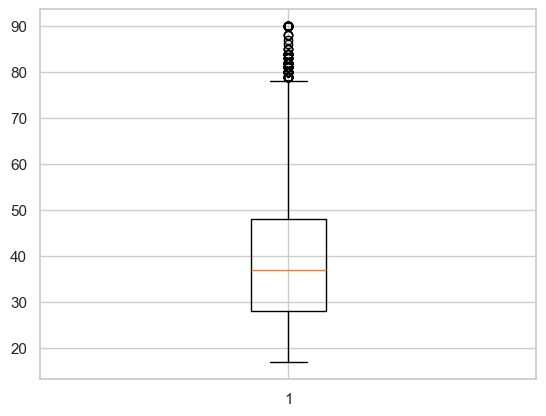

In [437]:
plt.boxplot(df['age'])
plt.show()

In [438]:
X_train.describe()


,age,fnlwgt,education.num,capital.gain,capital.loss,hours.per.week,native.country,workclass_Local-gov,workclass_Never-worked,workclass_Private,...,occupation_Transport-moving,relationship_Not-in-family,relationship_Other-relative,relationship_Own-child,relationship_Unmarried,relationship_Wife,race_Asian-Pac-Islander,race_Black,race_Other,race_White
count,26029.000000,2.602900e+04,26029.000000,26029.000000,26029.000000,26029.000000,26029.000000,26029.000000,26029.000000,26029.000000,...,26029.000000,26029.000000,26029.000000,26029.000000,26029.000000,26029.000000,26029.000000,26029.000000,26029.000000,26029.000000
mean,38.503899,1.898300e+05,10.080026,1095.658112,88.634638,40.438857,36.424911,0.063737,0.000231,0.755081,...,0.048830,0.254870,0.029928,0.156134,0.105306,0.047716,0.032233,0.095663,0.008759,0.853433
std,13.620717,1.058565e+05,2.572495,7466.778071,406.625857,12.287118,6.051291,0.244288,0.015181,0.430048,...,0.215517,0.435796,0.170392,0.362989,0.306953,0.213169,0.176622,0.294134,0.093183,0.353681
min,17.000000,1.228500e+04,1.000000,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,28.000000,1.177670e+05,9.000000,0.000000,0.000000,40.000000,38.000000,0.000000,0.000000,1.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000
50%,37.000000,1.783120e+05,10.000000,0.000000,0.000000,40.000000,38.000000,0.000000,0.000000,1.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000
75%,47.000000,2.369850e+05,12.000000,0.000000,0.000000,45.000000,38.000000,0.000000,0.000000,1.000000,...,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000
max,90.000000,1.484705e+06,16.000000,99999.000000,4356.000000,99.000000,40.000000,1.000000,1.000000,1.000000,...,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000


In [439]:
from sklearn.linear_model import LogisticRegression

In [440]:
model = LogisticRegression(
    
    C = 1.0,
    # solver='lbfgs',
    max_iter=10000,
    fit_intercept=True,
)

In [441]:
model.fit(X_train , y_train)

/Users/pawn/Library/Python/3.9/lib/python/site-packages/sklearn/linear_model/_logistic.py:469: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. of ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


LogisticRegression(max_iter=10000)

In [442]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score , classification_report

In [443]:
y_pred = model.predict(X_test)

In [444]:
score = accuracy_score(y_test , y_pred)
print(score)

0.8451137062077443


In [445]:
clas = classification_report(y_test , y_pred)
print(clas)

              precision    recall  f1-score   support

       <=50K       0.88      0.93      0.90      4940
        >50K       0.72      0.59      0.65      1568

    accuracy                           0.85      6508
   macro avg       0.80      0.76      0.77      6508
weighted avg       0.84      0.85      0.84      6508



In [446]:
from sklearn.preprocessing import MinMaxScaler
my_scaler = MinMaxScaler(feature_range=(0, 1))
X_train[['age']] = my_scaler.fit_transform(X_train[['age']])
X_test[['age']] = my_scaler.transform(X_test[['age']])


In [447]:
X_train['age'].min(), X_train['age'].max() , X_train['age'].mean()


(np.float64(0.0), np.float64(1.0), np.float64(0.2945739657084274))

In [448]:
from imblearn.over_sampling import SMOTE
smote = SMOTE(random_state=42)
X_train_smote, y_train_smote = smote.fit_resample(X_train, y_train)
print("X_train_smote = ",X_train_smote.shape ," y_train_smote = ", y_train_smote.shape)

X_train_smote =  (39516, 57)  y_train_smote =  (39516,)


In [449]:
y_train_smote.value_counts()

income
<=50K    19758
>50K     19758
Name: count, dtype: int64

In [450]:
results = []

# Logistic Regression
model = LogisticRegression()
model.fit(X_train, y_train)
y_pred = model.predict(X_test)

results.append({
    'Method': "Normal Data",
    'Accuracy': accuracy_score(y_test, y_pred),
    # 'Precision': precision_score(y_test, y_pred),
    # 'Recall': recall_score(y_test, y_pred),
    # 'F1-Score': f1_score(y_test, y_pred)
})

/Users/pawn/Library/Python/3.9/lib/python/site-packages/sklearn/linear_model/_logistic.py:469: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. of ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


In [451]:
# Install the imbalanced-learn library if it is not already available
!pip install imbalanced-learn

from imblearn.over_sampling import (
    SMOTE,
    ADASYN,
    RandomOverSampler,
    BorderlineSMOTE,
    SVMSMOTE,
)

# Apply SMOTE to balance the training set
smote = SMOTE(k_neighbors=5, random_state=42)
X_train_smote, y_train_smote = smote.fit_resample(X_train, y_train)

print('X_train_smote =', X_train_smote.shape, 'y_train_smote =', y_train_smote.shape)


zsh:1: command not found: pip
X_train_smote = (39516, 57) y_train_smote = (39516,)


In [452]:
# Logistic Regression Using Smote Over Sampling
model = LogisticRegression()
model.fit(X_train_smote, y_train_smote)
y_pred = model.predict(X_test)

results.append({
    'Method': "SMOTE Over Sampling",
    'Accuracy': accuracy_score(y_test, y_pred),
    # 'Precision': precision_score(y_test, y_pred),
    # 'Recall': recall_score(y_test, y_pred),
    # 'F1-Score': f1_score(y_test, y_pred)
})

/Users/pawn/Library/Python/3.9/lib/python/site-packages/sklearn/linear_model/_logistic.py:469: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. of ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


In [453]:
from imblearn.under_sampling import RandomUnderSampler
rus = RandomUnderSampler(random_state=42)
X_train_rus, y_train_rus = rus.fit_resample(X_train, y_train)
print("X_train_rus = ",X_train_rus.shape ," y_train_rus = ", y_train_rus.shape)

X_train_rus =  (12542, 57)  y_train_rus =  (12542,)


In [454]:
y_train_rus.value_counts()

income
<=50K    6271
>50K     6271
Name: count, dtype: int64

In [455]:
# Logistic Regression Using RandomOverSampler Under Sampling
model = LogisticRegression()
model.fit(X_train_rus, y_train_rus)
y_pred = model.predict(X_test)

results.append({
    'Method': "SMOTE Over Sampling",
    'Accuracy': accuracy_score(y_test, y_pred),
    # 'Precision': precision_score(y_test, y_pred),
    # 'Recall': recall_score(y_test, y_pred),
    # 'F1-Score': f1_score(y_test, y_pred)
})

/Users/pawn/Library/Python/3.9/lib/python/site-packages/sklearn/linear_model/_logistic.py:469: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. of ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


In [456]:
# Logistic Regression Using Class Weight Balanced

model = LogisticRegression(class_weight='balanced')
model.fit(X_train, y_train)
y_pred = model.predict(X_test)

results.append({
    'Method': "Class Weight Balanced",
    'Accuracy': accuracy_score(y_test, y_pred),
    # 'Precision': precision_score(y_test, y_pred),
    # 'Recall': recall_score(y_test, y_pred),
    # 'F1-Score': f1_score(y_test, y_pred)
})

/Users/pawn/Library/Python/3.9/lib/python/site-packages/sklearn/linear_model/_logistic.py:469: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. of ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


In [457]:
np.unique(y_train)

array(['<=50K', '>50K'], dtype=object)

In [458]:
results_df = pd.DataFrame(results).set_index('Method')
results_df

,Accuracy
Method,
Normal Data,0.786417
SMOTE Over Sampling,0.712815
SMOTE Over Sampling,0.719269
Class Weight Balanced,0.717425
